# Կեղծ լուրերի հայտնաբերում և աղբյուրներով ճշգրտում
## Գործնականի վերջնական նոթատետր
Գործարկել **Run → Run All Cells**։ Այս նոթատետրը իրականում մաքրում է տվյալները և ուսուցում սկզբնական համեմատական մոդելները։ Վերջնական, ավելի երկար ուսուցված մոդելները բեռնվում են պահպանված կշիռներից։ Դրանք կրկին ուսուցելու կարիք չկա ցուցադրության համար։

Միջերեսն ու բացատրությունները հայերեն են։ **Տվյալները և վերլուծվող տեքստերը անգլերեն են․ թարգմանված ուսուցման հավաքածու չունենք։** Սովորական գործարկումը առցանց ծառայություն չի կանչում, չի վերագրում վերջնական մոդելները և վճարովի բանալի չի պահանջում։

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'fakenews').is_dir():
    raise RuntimeError('Բացիր notebook-ը practical պանակից՝ open_notebook.command-ով։')
sys.path.insert(0, str(ROOT))
print('Նախագիծ՝', ROOT)
print('Python՝', sys.version.split()[0])
for asset in ['data/raw/liar/train.tsv','data/raw/fakenewsnet/politifact_fake.csv',
              'models/active_models.json','models/nli_deberta/model.safetensors']:
    assert (ROOT / asset).exists(), f'Բացակայում է՝ {asset}'
print('Անհրաժեշտ հիմնական ֆայլերն առկա են։')

Նախագիծ՝ /Users/macbook/Desktop/FakeNewsNet-master/practical
Python՝ 3.14.7
Անհրաժեշտ հիմնական ֆայլերն առկա են։


## 1. Տվյալների բեռնում և նախնական մշակում
LIAR-ը ունի վեց դաս, FakeNewsNet-ը՝ fake/real վերնագրեր։ Հեռացվում են դատարկ, կրկնվող և հակասող պիտակներով տեքստերը։ LIAR-ի պաշտոնական բաժանումը պահպանվում է մաքրումից հետո, FakeNewsNet-ը բաժանվում է 70/15/15։ Հատկանիշների բառապաշարը սովորում է միայն train-ից։

In [2]:
from fakenews.data import load_liar, load_fakenews, assert_disjoint, clean_text
frames, audits = {}, {}
frames['liar'], audits['liar'] = load_liar(ROOT/'data/raw/liar')
frames['fakenewsnet'], audits['fakenewsnet'] = load_fakenews(ROOT/'data/raw/fakenewsnet')
for frame in frames.values(): assert_disjoint(frame)
display(pd.DataFrame(audits).T)
display(pd.DataFrame({name: frame.groupby('split').size() for name,frame in frames.items()}))
print('Մաքրման օրինակ՝', clean_text('<p>Breaking NEWS!</p> https://example.org'))
display(frames['fakenewsnet'][['text','label','split']].head())

,raw_rows,empty_removed,conflicting_rows_removed,duplicates_removed,retained_rows
liar,12791,0,16,24,12751
fakenewsnet,23196,0,369,1239,21588


,liar,fakenewsnet
split,,
test,1262,3239
train,10212,15111
valid,1277,3238


Մաքրման օրինակ՝ breaking news! url


,text,label,split
0,BREAKING: First NFL Team Declares Bankruptcy O...,fake,train
1,Court Orders Obama To Pay $400 Million In Rest...,fake,train
2,UPDATE: Second Roy Moore Accuser Works For Mic...,fake,train
3,Oscar Pistorius Attempts To Commit Suicide,fake,train
4,Trump Votes For Death Penalty For Being Gay,fake,train


## 2. Հատկանիշներ և իրական ուսուցում
Ստորև ամբողջ մաքրված train-ով ուսուցվում են TF-IDF + majority, Naive Bayes, Logistic Regression և SVM տարբերակները՝ երկու հավաքածուների համար։ Սա կարող է տևել մի քանի րոպե։ Ընտրությունը կատարվում է միայն validation macro-F1-ով։ Վերջնական ակտիվ մոդելները չեն փոխվում։

In [3]:
from fakenews.train import candidates, pipeline, metrics
baseline_models, baseline_results = {}, []
for name, frame in frames.items():
    train = frame[frame.split=='train']
    valid = frame[frame.split=='valid']
    fitted, comparisons = {}, []
    for model_name, estimator in candidates().items():
        started = time.perf_counter()
        model = pipeline(estimator).fit(train.text, train.label)
        fitted[model_name] = model
        comparisons.append({'model':model_name, **metrics(valid.label, model.predict(valid.text))})
        print(name, model_name, round(time.perf_counter()-started,1), 'վայրկյան')
    comparison = pd.DataFrame(comparisons).sort_values('macro_f1', ascending=False)
    display(comparison[['model','accuracy','macro_f1']])
    winner = comparison.iloc[0]['model']
    baseline_models[name] = fitted[winner]
    test = frame[frame.split=='test']
    baseline_results.append({'dataset':name,'selected':winner,
        **metrics(test.label, fitted[winner].predict(test.text))})
display(pd.DataFrame(baseline_results)[['dataset','selected','accuracy','macro_f1']])
vectorizer = baseline_models['fakenewsnet'].named_steps['tfidf']
print('TF-IDF հատկանիշների քանակը՝', len(vectorizer.get_feature_names_out()))
print('Հատկանիշների օրինակներ՝', vectorizer.get_feature_names_out()[:20])

liar majority 0.2 վայրկյան


liar complement_nb 0.2 վայրկյան


liar logistic_regression 1.1 վայրկյան


liar linear_svm 0.3 վայրկյան


,model,accuracy,macro_f1
2,logistic_regression,0.257635,0.259639
3,linear_svm,0.246672,0.249019
1,complement_nb,0.251370,0.248845
0,majority,0.194205,0.054208


...

fakenewsnet logistic_regression 0.3 վայրկյան


fakenewsnet linear_svm 0.3 վայրկյան


,model,accuracy,macro_f1
2,logistic_regression,0.819951,0.768803
1,complement_nb,0.829524,0.763592
3,linear_svm,0.819024,0.762091
0,majority,0.759419,0.431631


,dataset,selected,accuracy,macro_f1
0,liar,logistic_regression,0.249604,0.249007
1,fakenewsnet,logistic_regression,0.823711,0.767928


TF-IDF հատկանիշների քանակը՝ 24551
Հատկանիշների օրինակներ՝ ['000' '000 credit' '000 for' '000 month' '000 to' '000 worth' '05' '10'
 '10 000' '10 best' '10 biggest' '10 celebrity' '10 days' '10 highest'
 '10 million' '10 minutes' '10 months' '10 most' '10 of' '10 photos']


## 3. Վերջնական բարելավված մոդելները
Վերջնական մոդելը MiniLM-ի լրացուցիչ ուսուցված դասակարգչի և ոչ նեյրոնային մոդելի 50/50 համադրություն է։ Յուրաքանչյուր հավաքածուի համար նախկինում համեմատվել է 30 տարբերակ՝ validation-ով։ Այստեղ դիտում ենք ուսուցման պատմությունը և վերահաշվում պահպանված թեստային կանխատեսումների չափումները։ Այս բջիջը **չի վերաուսուցում** լեզվային մոդելները։

liar ուսուցման պատմություն


,epoch,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,seconds,mean_loss
0,1,0.260767,0.237191,0.228990,0.237191,0.200538,0.210788,86.029571,1.774299
1,2,0.271731,0.274070,0.267289,0.274070,0.264975,0.264113,81.895990,1.716430
2,3,0.264683,0.267268,0.268997,0.267268,0.262159,0.260845,94.088905,1.662432
3,4,0.264683,0.273002,0.264758,0.273002,0.263835,0.260477,94.483275,1.613097


fakenewsnet ուսուցման պատմություն


,epoch,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,seconds,mean_loss
0,1,0.803582,0.792624,0.742914,0.792624,0.758422,0.812615,150.435462,0.548079
1,2,0.845584,0.802298,0.787255,0.802298,0.794196,0.847553,216.249346,0.410085
2,3,0.848054,0.790331,0.792392,0.790331,0.791351,0.847786,294.280037,0.352287
3,4,0.844966,0.796629,0.786807,0.796629,0.791473,0.846271,285.947183,0.312881


,dataset,test_count,accuracy,macro_f1
0,liar,1262,0.263074,0.263848
1,fakenewsnet,3239,0.857055,0.795602


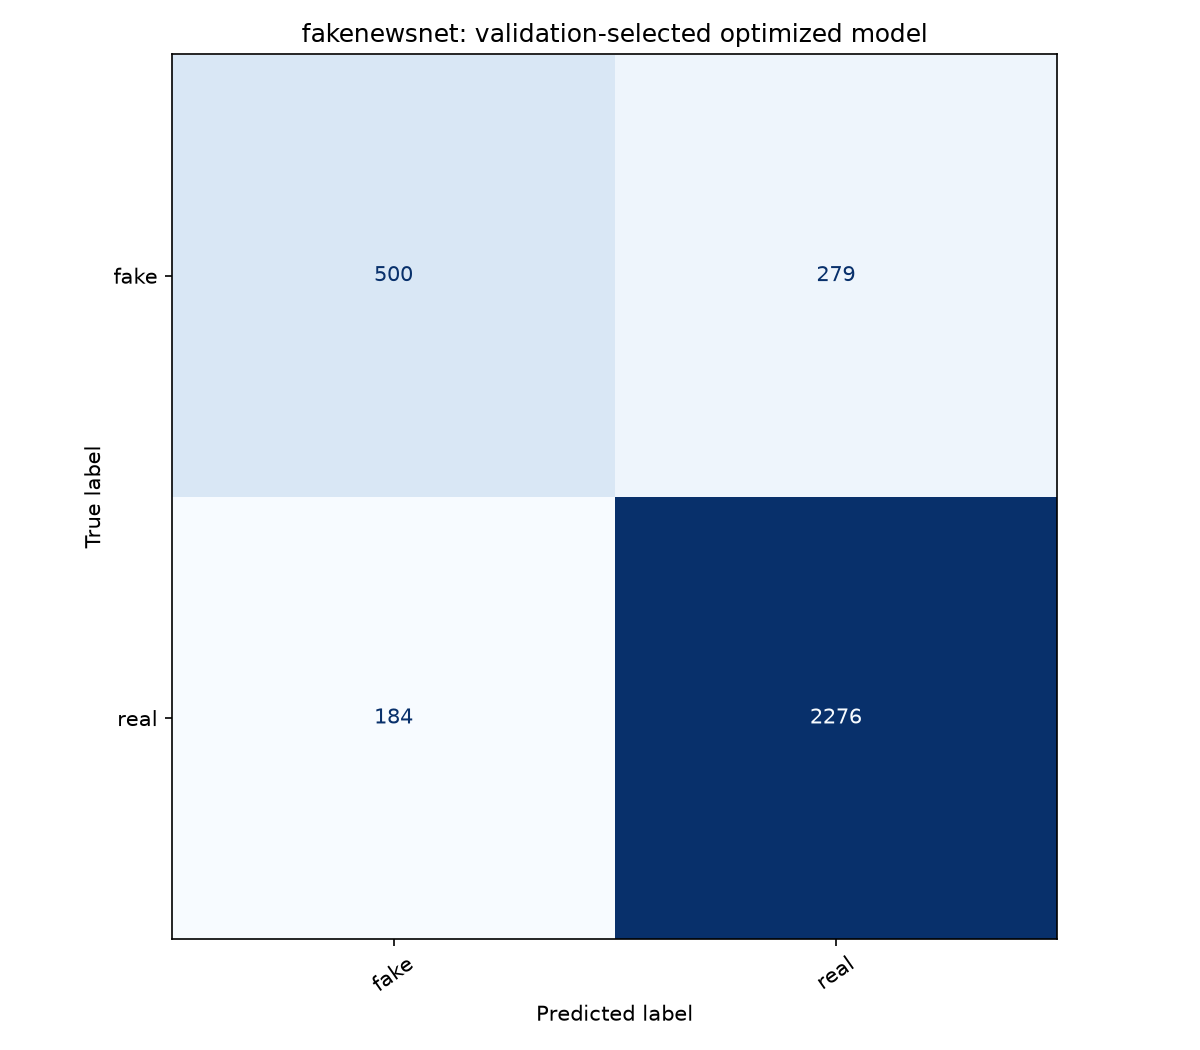

In [4]:
final_rows=[]
for name in ['liar','fakenewsnet']:
    folder=ROOT/'reports/optimization'/name
    saved=json.loads((folder/'test_metrics.json').read_text())
    predictions=pd.read_csv(folder/'test_predictions.csv')
    actual=metrics(predictions.label, predictions.prediction)
    assert np.isclose(actual['accuracy'], saved['accuracy'])
    final_rows.append({'dataset':name,'test_count':len(predictions),
                       'accuracy':actual['accuracy'],'macro_f1':actual['macro_f1']})
    print(name, 'ուսուցման պատմություն')
    display(pd.DataFrame(json.loads((folder/'training_history.json').read_text())))
display(pd.DataFrame(final_rows))
display(Image(filename=str(ROOT/'reports/optimization/fakenewsnet/confusion_matrix.png'),width=620))

## 3ա. Փուլ 2՝ նիշային n-gram-ներ, աղբյուրի տիրույթ, LIAR-ի մետատվյալներ
Փուլ 1-ի նեյրոնային համադրության հավանականությունները համադրվում են նոր լոգիստիկ ռեգրեսիայի հետ՝ p = α·p_neural + (1−α)·p_LR։ α կշիռը և որոշման շեմը ընտրված են միայն validation-ով։ FakeNewsNet-ի «տիրույթ» մոդելը օգտագործվում է միայն այն դեպքում, երբ հայտնի է լուրի հղումը։ Վերաուսուցման համար՝ `python -m fakenews.improve_v2`։ Այս բջիջը վերաուսուցում չի կատարում․ այն վերահաշվում է պահպանված մոդելի թեստային կանխատեսումները։

,model,threshold,val_macro_f1,accuracy,macro_f1,fake_precision,fake_recall
0,stage1_neural_ensemble,0.47,0.8076,0.8564,0.7978,0.7193,0.6611
1,lr_word+char,0.59,0.7848,0.8379,0.7698,0.6819,0.6110
2,stack_neural+word+char,0.50,0.8102,0.8580,0.7982,0.7288,0.6521
3,lr_word+char+domain,0.57,0.8116,0.8682,0.8122,0.7543,0.6701
4,stack_neural+word+char+domain,0.55,0.8233,0.8743,0.8177,0.7844,0.6585


,task,model,accuracy,macro_f1,macro_precision,macro_recall
0,6-class,stage1_neural_ensemble,0.2631,0.2638,0.2641,0.2661
1,6-class,lr_text,0.2528,0.2493,0.2474,0.2539
2,6-class,stack_neural+text (w=1.0),0.2631,0.2638,0.2641,0.2661
3,6-class,lr_text+metadata,0.2599,0.2603,0.2585,0.2748
4,6-class,stack_neural+text+metadata (w=0.6),0.2797,0.2833,0.2809,0.2920
5,binary,stage1_neural_ensemble,0.6474,0.6321,0.6407,0.6317
6,binary,lr_text,0.6307,0.6270,0.6268,0.6282
7,binary,stack_neural+text (w=0.5),0.6418,0.6322,0.6346,0.6315
8,binary,lr_text+metadata,0.6474,0.6389,0.6405,0.6383
9,binary,stack_neural+text+metadata (w=0.8),0.6601,0.6454,0.6544,0.6446


text α = 0.8 շեմ = 0.5 accuracy = 0.858 macro-F1 = 0.7982
domain α = 0.5 շեմ = 0.55 accuracy = 0.8743 macro-F1 = 0.8177


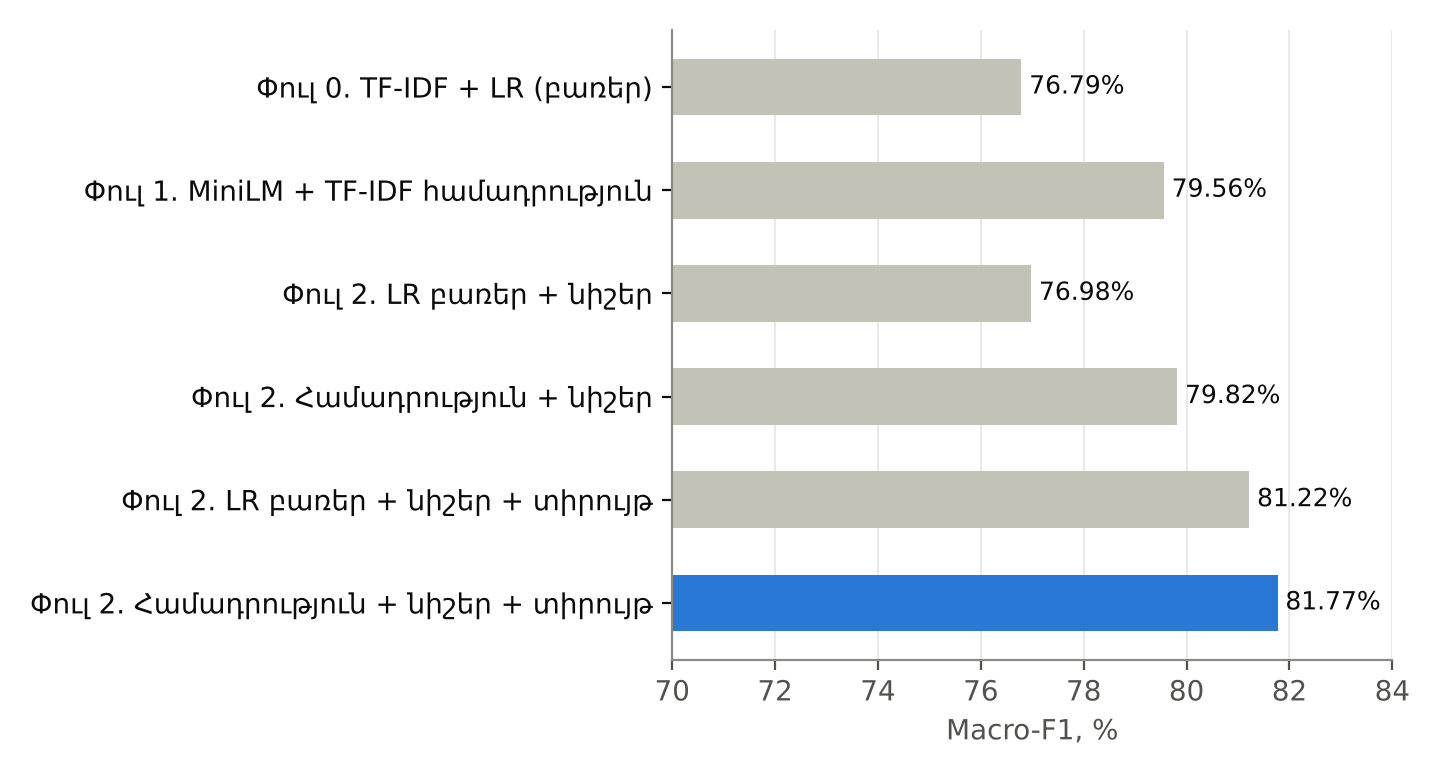

In [5]:
import joblib
v2_results=pd.read_csv(ROOT/'reports/v2/fakenewsnet_v2_results.csv')
display(v2_results[['model','threshold','val_macro_f1','accuracy','macro_f1','fake_precision','fake_recall']])
display(pd.read_csv(ROOT/'reports/v2/liar_v2_results.csv'))
v2=joblib.load(ROOT/'models/fakenewsnet_v2.joblib')
manifest=pd.read_csv(ROOT/'reports/fakenewsnet/split_manifest.csv'); test_rows=manifest[manifest.split=='test'].reset_index(drop=True)
urls=pd.concat([pd.read_csv(ROOT/f'data/raw/fakenewsnet/{s}_{l}.csv',usecols=['id','news_url']) for s in ['politifact','gossipcop'] for l in ['fake','real']]).drop_duplicates('id')
test_rows=test_rows.merge(urls,on='id',how='left')
stage1_probs=np.load(ROOT/'reports/optimization/fakenewsnet/test_probabilities.npy')
for kind in ['text','domain']:
    model=v2['models'][kind]
    pred=model.decide(model.combine(stage1_probs, model.features.frame(test_rows.text.tolist(), test_rows.news_url.tolist())))
    m=metrics(test_rows.label, pred)
    print(kind, 'α =', model.alpha, 'շեմ =', model.threshold, 'accuracy =', round(m['accuracy'],4), 'macro-F1 =', round(m['macro_f1'],4))
display(Image(filename=str(ROOT/'reports/v2/fig_fnn_v2.png'),width=620))

## 3բ. Փուլեր 3–4՝ տրանսֆորմերներ և մետա-մոդել (աշխատող տարբերակը)
RoBERTa-base, ELECTRA-base և «վերնագիր + հղման բառեր» RoBERTa մոդելները լրացուցիչ ուսուցված են FakeNewsNet-ով (`train_transformer.py`), իսկ բոլոր բաղադրիչների «կեղծ» հավանականությունների logit-ները միավորվում են լոգիստիկ մետա-մոդելով (`stack_v4.py`)։ Կշիռներն ու շեմը ընտրված են վավերացման բազմության 5-ապատիկ խաչաձև ստուգմամբ։ Ստորև թեստային չափումները **վերահաշվարկվում են** պահպանված թեստային հավանականություններից և շեմից, ոչ թե պարզապես կարդացվում։

In [6]:
v4_metrics=json.loads((ROOT/'reports/v4/fakenewsnet_v4_deployed_metrics.json').read_text())
y_test=test_rows.label.values
rows=[]
for kind,title in [('text','Փուլ 4, միայն տեքստ'),('domain','Փուլ 4, տեքստ + հղում')]:
    p_fake=np.load(ROOT/f'reports/v4/fakenewsnet_v4_{kind}_test_fake_proba.npy')
    pred=np.where(p_fake>=v4_metrics[kind]['threshold'],'fake','real')
    m=metrics(y_test,pred)
    assert abs(m['macro_f1']-v4_metrics[kind]['macro_f1'])<1e-3, 'չափումը չի վերարտադրվել'
    rows.append({'մոդել':title,'բաղադրիչներ':', '.join(v4_metrics[kind]['components']),'շեմ':v4_metrics[kind]['threshold'],
                 'accuracy':round(m['accuracy'],4),'macro-F1':round(m['macro_f1'],4)})
display(pd.DataFrame(rows))
v3=pd.read_csv(ROOT/'reports/v3/fakenewsnet_v3_results.csv')
print('Փուլ 3-ի (RoBERTa + փուլեր 1–2) համեմատությունը՝'); display(v3.head(6))
liar_v4=json.loads((ROOT/'reports/v4/liar_v4_summary.json').read_text())
print('LIAR, փուլ 4 (', ' + '.join(liar_v4['components']), '):', liar_v4['selected_test'])

,մոդել,բաղադրիչներ,շեմ,accuracy,macro-F1
0,"Փուլ 4, միայն տեքստ","stage1, roberta, electra, lr_text",0.33,0.8608,0.8090
1,"Փուլ 4, տեքստ + հղում","stage1, roberta, electra, rb_url, lr_text, lr_...",0.47,0.8870,0.8354


Փուլ 3-ի (RoBERTa + փուլեր 1–2) համեմատությունը՝


,model,threshold,val_macro_f1,accuracy,macro_f1,macro_precision,macro_recall,fake_precision,fake_recall
0,large_alone,0.50,0.8074,0.8589,0.8022,0.8101,0.7953,0.7218,0.6727
1,stage2_text,0.50,0.8102,0.8580,0.7982,0.8111,0.7876,0.7288,0.6521
2,"stage3_text (large=0.4, stage1=0.5)",0.45,0.8179,0.8605,0.8077,0.8099,0.8055,0.7143,0.6996
3,stage2_domain,0.55,0.8233,0.8743,0.8177,0.8408,0.8006,0.7844,0.6585
4,"stage3_domain (large=0.2, stage1=0.2)",0.54,0.8320,0.8790,0.8265,0.8444,0.8124,0.7850,0.6842


LIAR, փուլ 4 ( stage1 + rb_meta + lr_metadata ): {'accuracy': 0.2861, 'macro_f1': 0.2887, 'macro_precision': 0.2864, 'macro_recall': 0.2965}


## 3գ. Փուլ 5՝ սոցիալական համատեքստ (հետազոտական)
FakeNewsNet-ում յուրաքանչյուր լուրի համար տրված են այն տարածած թվիթների նույնացուցիչները։ Snowflake ID-ի վերին բիթերը պարունակում են թվիթի ստեղծման պահը՝ `t = (id >> 22) + 1288834974657` մվ, ուստի տարածման ժամանակային շարքը վերականգնվում է **առանց Twitter API-ի** (`fakenews/social.py`)։ Բացարձակ ամսաթիվը չի օգտագործվում, որպեսզի մոդելը չսովորի տվյալների հավաքման տարեթվերը։ Ստորև հատկանիշները հաշվարկվում են մեկ իրական լուրի համար, իսկ հետո ցուցադրվում են պահպանված արդյունքները (`python -m fakenews.social`, ~1 րոպե)։

Saudi Arabia to Behead 6 School Girls for Being With Their Male Friends Without Parents or a Guardian | fake | 202 թվիթ


,log_tweets,has_tweets,untimed_share,log_span_h,log_median_gap_h,burstiness,log_t50_h,log_t90_h,share_first_1h,log_tweets_first_1h,share_first_6h,log_tweets_first_6h,share_first_24h,log_tweets_first_24h,share_first_168h,log_tweets_first_168h
արժեք,5.313,1.0,0.0,8.884,0.529,0.852,4.521,5.274,0.01,1.099,0.015,1.386,0.059,2.565,0.847,5.147


,model,val_macro_f1,accuracy,macro_f1,fake_precision,fake_recall
0,social only (gradient boosting),0.8506,0.8978,0.8590,0.7947,0.7754
1,social_24h only (gradient boosting),0.7877,0.8620,0.8021,0.7448,0.6483
2,social_with_year only (gradient boosting),0.8615,0.9061,0.8701,0.8154,0.7882
3,stage4 text (reference),0.8175,0.8608,0.8090,0.7119,0.7073
4,stage4 text + url (reference),0.8454,0.8870,0.8354,0.8192,0.6804
5,text + social,0.9147,0.9358,0.9114,0.8752,0.8549
6,text + url + social,0.9231,0.9441,0.9236,0.8833,0.8845
7,text + social 24h,0.8872,0.9061,0.8723,0.7995,0.8139
8,text + url + social 24h,0.9058,0.9247,0.8967,0.8452,0.8408


Macro-F1-ի աճի 95% bootstrap միջակայքեր՝


{'text + social vs stage4 text': [0.0873, 0.1189],
 'text + url + social vs stage4 text + url': [0.0747, 0.1034],
 'text + url + social 24h vs stage4 text + url': [0.0475, 0.0768]}

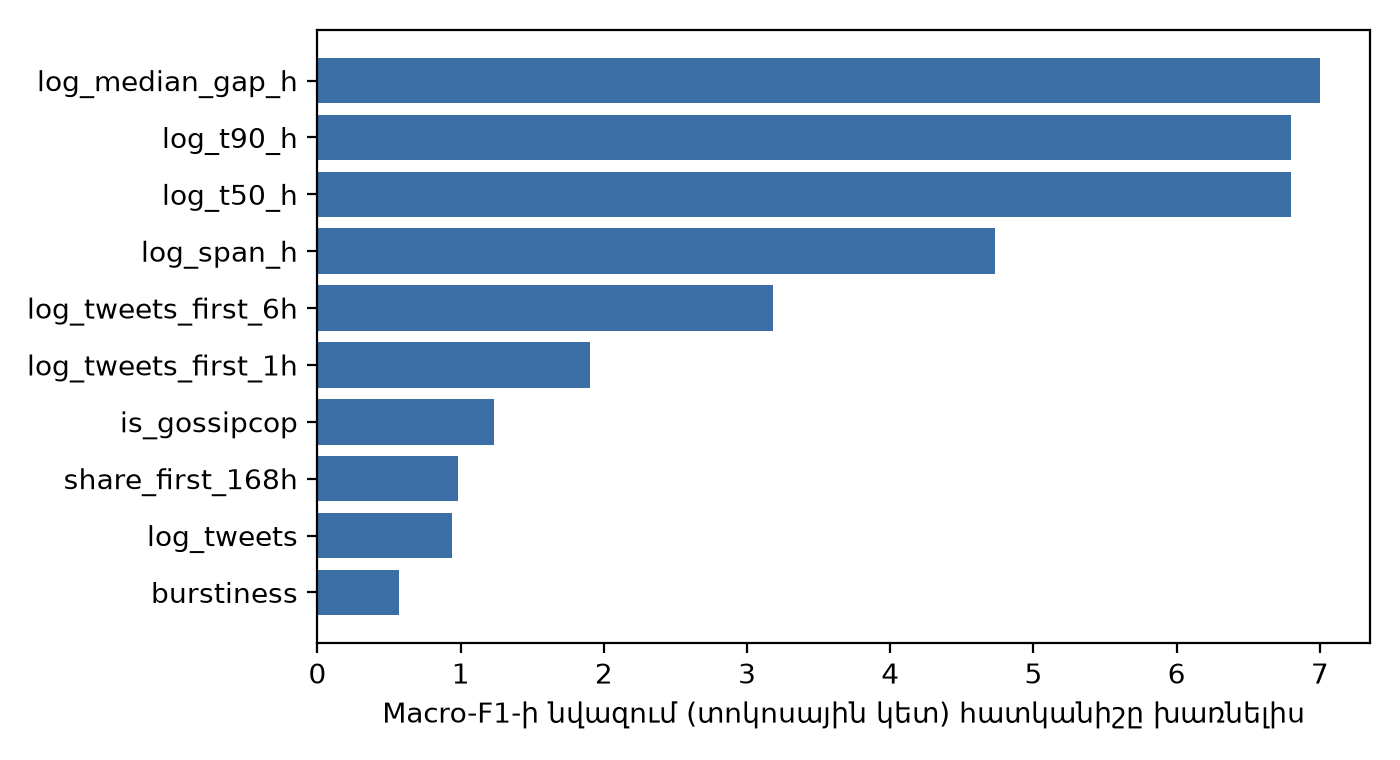

Փուլ 5-ը API-ում ներդրված չէ․ նոր լուրի թվիթները հասանելի են միայն տարածումից հետո։


In [7]:
from fakenews.social import load_frame, propagation_features
social_frame=load_frame()
example=social_frame[(social_frame.split=='test')&(social_frame.tweet_ids.fillna('').str.split().str.len()>20)].iloc[0]
print(example.text,'|',example.label,'|',len(example.tweet_ids.split()),'թվիթ')
display(pd.Series(propagation_features(example.tweet_ids)).round(3).to_frame('արժեք').T)
v5=pd.read_csv(ROOT/'reports/v5/fakenewsnet_v5_results.csv')
display(v5[['model','val_macro_f1','accuracy','macro_f1','fake_precision','fake_recall']])
v5_summary=json.loads((ROOT/'reports/v5/fakenewsnet_v5_summary.json').read_text())
print('Macro-F1-ի աճի 95% bootstrap միջակայքեր՝'); display(v5_summary['macro_f1_diff_95ci'])
display(Image(filename=str(ROOT/'reports/v5/fig_social_importance.png'),width=560))
print('Փուլ 5-ը API-ում ներդրված չէ․ նոր լուրի թվիթները հասանելի են միայն տարածումից հետո։')

## 3դ. Սխալների վերլուծություն
`python -m fakenews.error_analysis` — սխալներն ըստ աղբյուրի, թվիթների քանակի և վերնագրի երկարության, տրամաչափումը (Brier, ECE) և բնորոշ օրինակներ։

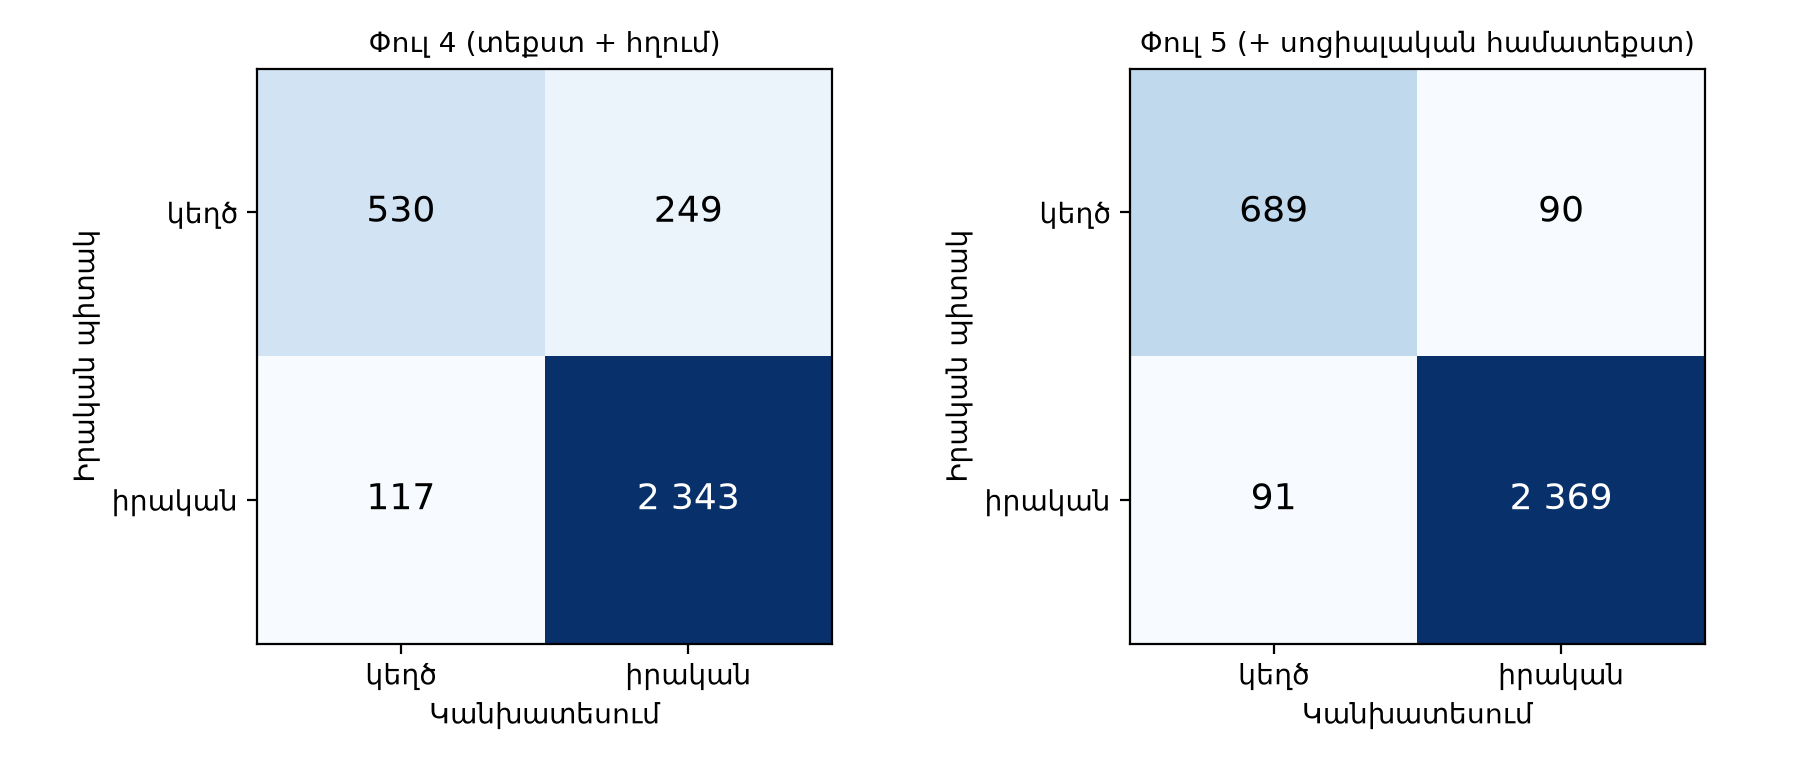

Փուլ 5-ն ուղղել է 242 սխալ, ավելացրել՝ 57 , երկուսն էլ սխալ՝ 124


,bucket,rows,fake_share,pred_stage4_error_rate,pred_stage4_macro_f1,pred_v5_error_rate,pred_v5_macro_f1
0,0,235,0.1532,0.0809,0.8424,0.0809,0.8424
1,1–9,533,0.5422,0.1745,0.8253,0.0901,0.9091
2,10–99,2155,0.1485,0.0854,0.8276,0.0367,0.9276
3,≥100,316,0.4241,0.2215,0.7549,0.1108,0.8860


,brier,ece_10_bins
pred_stage4,0.0831,0.0140
pred_v5,0.0421,0.0082


false_negative


,source,label,n_tweets,text
0,gossipcop,fake,3,Aritzia Says Meghan Markle Boosted Earnings; W...
1,gossipcop,fake,159,Amal Clooney changed dresses during the Met Ga...
2,gossipcop,fake,1,"Sean Spicer Says 'SNL' Went ""Over the Line"" in..."
3,gossipcop,fake,2,This Is Us’ Justin Hartley on ‘Best Friends’ M...
4,politifact,fake,29060,The Legislative Process


false_positive


,source,label,n_tweets,text
0,gossipcop,real,125,Celebrity Couples Who Prove That Love Isn’t Dead
1,gossipcop,real,24,Kendall Jenner’s latest date night with Ben Si...
2,gossipcop,real,17,Kate Hudson Calls Brad Pitt Dating Rumors the ...
3,gossipcop,real,4,Pregnant Khloé Kardashian and Kylie Jenner Bon...
4,politifact,real,40,"UN Refugee Agency welcomes arrival of 10,000th..."


In [8]:
errors=json.loads((ROOT/'reports/v5/error_analysis.json').read_text())
display(Image(filename=str(ROOT/'reports/v5/fig_confusion_v4_v5.png'),width=640))
print('Փուլ 5-ն ուղղել է', errors['fixed_by_social'], 'սխալ, ավելացրել՝', errors['broken_by_social'], ', երկուսն էլ սխալ՝', errors['errors_in_both'])
display(pd.DataFrame(errors['by_tweets']))
display(pd.DataFrame(errors['calibration']).T)
for kind in ['false_negative','false_positive']:
    print(kind); display(pd.DataFrame(errors['examples'][kind])[['source','label','n_tweets','text']].head(5))

## 4. Քո նոր տեքստի դասակարգումը
Փոխիր միայն `MY_TEXT`-ը և գործարկիր բջիջը։ `standard`, `balanced`, `high_recall` ռեժիմները փոխում են դասակարգման շեմը։ Զգայուն ռեժիմը բաց է թողնում ավելի քիչ կեղծ լուրեր, բայց ավելացնում է սխալ ահազանգերը։ Դասակարգչի կանխատեսումը փաստացի ճշմարտության ապացույց չէ։

In [9]:
from fastapi.testclient import TestClient
from fakenews.app import app
client=TestClient(app)
MY_TEXT = 'BREAKING: Famous actress secretly married in Las Vegas, insiders reveal!'
MODE = 'standard'
SOURCE_URL = 'https://hollywoodlife.com/2018/05/05/celebrity-wedding/'   # ոչ պարտադիր․ էջը չի բեռնվում, օգտագործվում են տիրույթն ու ուղու բառերը
body={'text':MY_TEXT,'dataset':'fakenewsnet','decision_mode':MODE,'explain':True}
if SOURCE_URL: body['source_url']=SOURCE_URL
response=client.post('/analyze',json=body)
response.raise_for_status()
result=response.json()
display({key:result[key] for key in ['model_prediction','model_version','decision_mode','decision_threshold','model_scores','seen_in_training']})
if result.get('explanation'):
    print('Ամենաազդեցիկ բառերը (Δ = հավանականության փոփոխություն բառը հեռացնելիս)՝')
    display(pd.DataFrame(result['explanation'].get('words', result['explanation']) if isinstance(result['explanation'],dict) else result['explanation']).head(8))
display(pd.DataFrame(json.loads((ROOT/'reports/reliability/decision_modes_test.json').read_text())).T)
print('Միավորները ճշմարտության հավանականություններ չեն։')

/Users/macbook/Desktop/FakeNewsNet-master/practical/.venv/lib/python3.14/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


/Users/macbook/Desktop/FakeNewsNet-master/practical/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 26174.69it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

...

{'model_prediction': 'fake',
 'model_version': 'stage4_domain',
 'decision_mode': 'standard',
 'decision_threshold': 0.47,
 'model_scores': {'fake': 0.9749082683249898, 'real': 0.02509173167501022},
 'seen_in_training': False}

Ամենաազդեցիկ բառերը (Δ = հավանականության փոփոխություն բառը հեռացնելիս)՝


,word,position,effect
0,BREAKING:,0,0.0148
1,secretly,3,0.0063


,accuracy,macro_f1,fake_precision,fake_recall,false_negatives,false_positives,threshold
previous_argmax,0.857055,0.795602,0.730994,0.641849,279.0,184.0,0.50
balanced,0.856437,0.797823,0.719274,0.661104,264.0,201.0,0.47
high_recall,0.825255,0.780773,0.606394,0.779204,172.0,394.0,0.30


Միավորները ճշմարտության հավանականություններ չեն։


## 4ա. Հայերեն և ռուսերեն մուտք
Մոդելներն ուսուցված են անգլերենով, ուստի հայերեն և ռուսերեն տեքստը նախ տեղում թարգմանվում է NLLB-200 մոդելով (`fakenews/translate.py`)։ Առաջին գործարկումը կարող է տևել մոտ մեկ րոպե՝ թարգմանության մոդելի բեռնման պատճառով։ Շրջադարձային գնահատմամբ macro-F1-ը 82.50% է անգլերենի, 78.13% հայերենի և 79.90% ռուսերենի համար։

In [10]:
for text in ['Հայտնի դերասանուհին գաղտնի ամուսնացել է Լաս Վեգասում', 'Сенат США одобрил новый бюджет на 2018 год']:
    r=client.post('/analyze',json={'text':text,'dataset':'fakenewsnet'}).json()
    print(f"{text}\n  լեզու՝ {r.get('detected_language')} → {r.get('translated_text')}\n  կանխատեսում՝ {r['model_prediction']} ({r['model_version']})\n")
display(json.loads((ROOT/'reports/translation/round_trip_metrics.json').read_text()))


Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 509/509 [00:00<00:00, 8432.34it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Հայտնի դերասանուհին գաղտնի ամուսնացել է Լաս Վեգասում
  լեզու՝ hy → Famous actress secretly married in Las Vegas
  կանխատեսում՝ fake (stage4_text)



[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Сенат США одобрил новый бюджет на 2018 год
  լեզու՝ ru → U.S. Senate approves new budget for 2018
  կանխատեսում՝ real (stage4_text)



{'n': 300,
 'english': {'accuracy': 0.8767,
  'macro_f1': 0.825,
  'macro_precision': 0.8378,
  'macro_recall': 0.8143,
  'fake_precision': 0.7692,
  'fake_recall': 0.6944},
 'hy': {'accuracy': 0.8467,
  'macro_f1': 0.7813,
  'macro_precision': 0.7944,
  'macro_recall': 0.7708,
  'fake_precision': 0.7031,
  'fake_recall': 0.625,
  'agreement_with_english': 0.91,
  'mean_abs_change_p_fake': 0.0848,
  'seconds': 275.5},
 'ru': {'accuracy': 0.8533,
  'macro_f1': 0.799,
  'macro_precision': 0.799,
  'macro_recall': 0.799,
  'fake_precision': 0.6944,
  'fake_recall': 0.6944,
  'agreement_with_english': 0.9233,
  'mean_abs_change_p_fake': 0.0714,
  'seconds': 182.5}}

## 5. Աղբյուրով ստուգում և ուղղման առաջարկ
Սա դասակարգումից առանձին գործողություն է։ Համակարգը որոնում է աղբյուրային հատված, գնահատում դրա կապը պնդման հետ և հնարավոր ուղղումը վերցնում աղբյուրից։ `live=False`՝ տեղային NASA աղբյուրներ։ Առցանց որոնումը ընտրովի է և ցուցադրության համար պետք չէ։

In [11]:
CLAIM = 'Mars has no moons.'
response=client.post('/verify',json={'text':CLAIM,'live':False})
response.raise_for_status()
verification=response.json()
print('Ելք՝', verification['status'])
print('Ուղղման առաջարկ՝', verification.get('corrected_text'))
for claim in verification['claims']:
    for evidence in claim.get('evidence',[])[:2]:
        print(evidence.get('text',''))
        print(evidence.get('source',{}).get('url',''))

/Users/macbook/Desktop/FakeNewsNet-master/practical/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 106/106 [00:00<00:00, 10875.38it/s]

Ելք՝ correction_proposed
Ուղղման առաջարկ՝ According to Mars: Facts - NASA Science: Mars has two small moons, Phobos and Deimos , that may be captured asteroids. [https://science.nasa.gov/mars/facts/]
Mars has two small moons, Phobos and Deimos , that may be captured asteroids.
https://science.nasa.gov/mars/facts/
The moons get their names from the horses that pulled the chariot of the Greek god of war, Ares (whose Roman counterpart is Mars).
https://science.nasa.gov/mars/facts/


## 6. Լրացուցիչ գիտական ռեժիմ՝ փորձնական
Գիտական տարբերակը առանձին ուսուցվել է SciFact-ով։ 659 ուսուցման պնդում, 150 կարգավորման պնդում և 300 առանձին գնահատման պնդում։ Ամբողջ շղթայի accuracy-ն 56.33% է․ այն **չի նշանակում ընդհանուր նորությունների ստուգման ճշտություն**։ Գիտական ռեժիմը ցույց է տալիս աղբյուրներ, բայց ինքնաշխատ նոր գիտական ձևակերպում չի ստեղծում։

In [12]:
science_metrics=json.loads((ROOT/'reports/reliability/scifact/holdout_metrics.json').read_text())
display({k:science_metrics[k] for k in ['count','accuracy','macro_f1_three_gold_classes','coverage']})
# Փոխիր պնդումը քո գիտական օրինակով՝ անգլերեն։
SCIENCE_CLAIM='1,000 genomes project enables mapping of genetic sequence variation consisting of rare variants.'
response=client.post('/verify-science',json={'text':SCIENCE_CLAIM})
response.raise_for_status()
scientific=response.json()
print('Գիտական գնահատական՝',scientific['status'])
for evidence in scientific['claims'][0]['evidence'][:1]:
    print(evidence['source']['title'])
    print(evidence['text'])

{'count': 300,
 'accuracy': 0.5633333333333334,
 'macro_f1_three_gold_classes': 0.5406835897401935,
 'coverage': 0.3433333333333333}

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 106/106 [00:00<00:00, 8910.46it/s]

Գիտական գնահատական՝ insufficient_evidence
Rare Variants Create Synthetic Genome-Wide Associations
Genome-wide association studies (GWAS) have now identified at least 2,000 common variants that appear associated with common diseases or related traits (http://www.genome.gov/gwastudies), hundreds of which have been convincingly replicated. It is generally thought that the associated markers reflect the effect of a nearby common (minor allele frequency >0.05) causal site, which is associated with the marker, leading to extensive resequencing efforts to find causal sites. We propose as an alternative explanation that variants much less common than the associated one may create "synthetic associations" by occurring, stochastically, more often in association with one of the alleles at the common site versus the other allele. Although synthetic associations are an obvious theoretical possibility, they have never been systematically explored as a possible explanation for GWAS findings. Here, we

## 7. Արդյունքի սահմանները և ցուցադրությունը
- FakeNewsNet (թեստ, 3 239 վերնագիր)՝ փուլ 0 (TF-IDF + LR) 76.79% macro-F1 → փուլ 4 (աշխատող մետա-մոդել) 80.90% միայն տեքստով և **83.54%** տեքստ + հղումով (88.70% accuracy)։ Փուլ 5-ը (հետազոտական, սոցիալական համատեքստով)՝ 92.36% macro-F1, միայն առաջին 24 ժամով՝ 89.67%։
- LIAR (6 դաս)՝ 24.90% → 28.87% macro-F1 (28.61% accuracy) մետատվյալներով։ Տարբեր խնդիրներ են, դրանց թվերը չենք միավորում։
- Փուլ 5-ի տարածման հատկանիշները հասանելի են միայն լուրի տարածումից հետո և կարող են մասամբ արտացոլել տվյալների հավաքման ընթացակարգը, ուստի աշխատող API-ն օգտագործում է փուլ 4-ը։
- Ընդհանուր աղբյուրներով շղթայի 75%-ը վերաբերում է ընդամենը 24 ձեռքով կազմված պնդումների։
- 112 ավտոմատ թեստերի անցնելը ծրագրի աշխատանքի ստուգում է, ոչ 100% կանխատեսման ճշտություն։
- Հայերեն և ռուսերեն տեքստերը մշակվում են մեքենայական թարգմանությամբ, հայերեն ուսուցման հավաքածու չկա։
- Թեստային արդյունքները արդեն դիտված են, ուստի հաջորդ բարելավումների համար անհրաժեշտ է նոր անկախ գնահատում։

**Պատրաստի միջերեսը բացելու համար** գործարկիր `start.command`, հետո բացիր http://127.0.0.1:8000 ։ Telegram բոտը՝ `telegram_bot.command` (token-ը `.env` ֆայլում)։ Notebook-ը կարող է աշխատել նաև առանց այդ կայքը միացնելու։

## 8. Կոդի քարտեզ և ամբողջական վերաուսուցում
Մաքրում՝ `fakenews/data.py`, սկզբնական ուսուցում՝ `train.py`, ընդլայնված համեմատություն՝ `optimize.py`, փուլ 2՝ `improve_v2.py` և `stacking.py`, փուլ 3՝ `train_large.py`, փուլ 4՝ `train_transformer.py` և `stack_v4.py`, փուլ 5՝ `social.py`, սխալների վերլուծություն՝ `error_analysis.py`, թարգմանություն՝ `translate.py`, բացատրություն՝ `explain.py`, Telegram բոտ՝ `telegram_bot.py`, մոդելների կառուցվածք՝ `advanced_models.py`, փաստաստուգում՝ `verify.py`, աղբյուրներ՝ `sources.py`, գիտական ուսուցում՝ `train_science_nli.py`, API՝ `app.py`։

Ամբողջական վերաուսուցումը երկար է և կարող է վերագրել արդյունքները։ Այն գործարկիր միայն նախագծի առանձին պատճենում՝ README.md-ի վերարտադրման հրամաններով։ Այս նոթատետրի սովորական Run All-ը բավարար է գործնական մեթոդը և աշխատող վերջնական մոդելները ցուցադրելու համար։